## `Pastikan klik 'File > Save a copy in Drive' sebelum memulai pengerjaan`

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.tseries.offsets import BDay

#Dataset

Data yang digunakan adalah data yang berasal dari Tokopedia (***bukan data sesungguhnya***). Mengenai penjelasan dataset adalah sebagai berikut:

|variable                       |class     |description |
|:------------------------------|:---------|:-----------|
**order_detail:**
id 			|object| angka unik dari order / id_order
customer_id 		|object|angka unik dari pelanggan
order_date 		|object| tanggal saat dilakukan transaksi
sku_id 			|object| angka unik dari produk (sku adalah stock keeping unit)
price			|int64| harga yang tertera pada tagging harga
qty_ordered 		|int64| jumlah barang yang dibeli oleh pelanggan
before_discount	|float64| nilai harga total dari produk (price * qty_ordered)
discount_amount	|float64| nilai diskon product total
after_discount		|float64| nilai harga total produk ketika sudah dikurangi dengan diskon
is_gross 		|int64| menunjukkan pelanggan belum membayar pesanan
is_valid		|int64| menunjukkan pelanggan sudah melakukan pembayaran
is_net			|int64| menunjukkan transaksi sudah selesai
payment_id 		|int64| angka unik dari metode pembayaran
||
**sku_detail:**
id |object| angka unik dari produk (dapat digunakan untuk key saat join)
sku_name 		|object| nama dari produk
base_price		|float64| harga barang yang tertera pada tagging harga / price
cogs 			|int64| cost of goods sold / total biaya untuk menjual 1 produk
category		|object| kategori produk
||
**customer_detail:**
id 			|object| angka unik dari pelanggan
registered_date	|object| tanggal pelanggan mulai mendaftarkan diri sebagai anggota
||
**payment_detail:**
id			|int64| angka unik dari metode pembayaran
payment_method	|object| metode pembayaran yang digunakan


In [3]:
#Sumber data yang digunakan
path_od = "https://raw.githubusercontent.com/dataskillsboost/FinalProjectDA11/main/order_detail.csv"
path_pd = "https://raw.githubusercontent.com/dataskillsboost/FinalProjectDA11/main/payment_detail.csv"
path_cd = "https://raw.githubusercontent.com/dataskillsboost/FinalProjectDA11/main/customer_detail.csv"
path_sd = "https://raw.githubusercontent.com/dataskillsboost/FinalProjectDA11/main/sku_detail.csv"
df_od = pd.read_csv(path_od)
df_pd = pd.read_csv(path_pd)
df_cd = pd.read_csv(path_cd)
df_sd = pd.read_csv(path_sd)

In [4]:
#Mengampilkan 5 baris pertama
df_od.head()

,id,customer_id,order_date,sku_id,price,qty_ordered,before_discount,discount_amount,after_discount,is_gross,is_valid,is_net,payment_id
0,ODR9939707760w,C713589L,2021-11-19,P858068,26100,200,5220000.0,2610000.00,2610000.00,1,1,0,5
1,ODR7448356649d,C551551L,2021-11-19,P886455,1971942,5,9859710.0,2464927.50,7394782.50,1,0,0,5
2,ODR4011281866z,C685596L,2021-11-25,P678648,7482000,1,7482000.0,2065344.62,5416655.38,1,0,0,4
3,ODR3378927994s,C830683L,2021-11-22,P540013,3593680,1,3593680.0,1455440.40,2138239.60,1,1,1,5
4,ODR4904430099k,C191766L,2021-11-21,P491032,4413220,1,4413220.0,1059172.80,3354047.20,1,1,1,4


In [5]:
#Mengampilkan 5 baris pertama
df_pd.head()

,id,payment_method
0,1,cod
1,2,jazzvoucher
2,3,customercredit
3,4,Payaxis
4,5,jazzwallet


In [6]:
#Mengampilkan 5 baris pertama
df_cd.head()

,id,registered_date
0,C996508L,2021-07-10
1,C180415L,2021-07-18
2,C535451L,2021-07-23
3,C177843L,2021-07-12
4,C951682L,2021-07-27


In [7]:
#Mengampilkan 5 baris pertama
df_sd.head()

,id,sku_name,base_price,cogs,category
0,P798444,AT-FSM-35,57631.70,46052,Kids & Baby
1,P938347,AYS_Haier-18HNF,3931789.26,3499256,Appliances
2,P826364,Atalian _DV206A-Brown-41,324597.00,243426,Men Fashion
3,P467533,Darul_Sakoon_Food_Bundle,2870.42,2378,Superstore
4,P229955,HP_15AY-15-Ay072NIA-ci3,2265625.00,1631250,Computing


In [8]:
#Menjalankan SQL di Colab
from sqlite3 import connect
conn = connect(':memory:')
df_od.to_sql('order_detail',conn, index=False, if_exists='replace')
df_pd.to_sql('payment_detail', conn, index=False, if_exists='replace')
df_sd.to_sql('sku_detail', conn, index=False, if_exists='replace')
df_cd.to_sql('customer_detail', conn, index=False, if_exists='replace')

3998

In [9]:
#Query SQL untuk menggabungkan data
df = pd.read_sql("""
SELECT
    order_detail.*,
    payment_detail.payment_method,
    sku_detail.sku_name,
    sku_detail.base_price,
    sku_detail.cogs,
    sku_detail.category,
    customer_detail.registered_date
FROM order_detail
LEFT JOIN payment_detail
    on payment_detail.id = order_detail.payment_id
LEFT JOIN sku_detail
    on sku_detail.id = order_detail.sku_id
LEFT JOIN customer_detail
    on customer_detail.id = order_detail.customer_id
""", conn)

In [10]:
#Mengampilkan 5 baris pertama
df.head()

,id,customer_id,order_date,sku_id,price,qty_ordered,before_discount,discount_amount,after_discount,is_gross,is_valid,is_net,payment_id,payment_method,sku_name,base_price,cogs,category,registered_date
0,ODR9939707760w,C713589L,2021-11-19,P858068,26100,200,5220000.0,2610000.00,2610000.00,1,1,0,5,jazzwallet,RB_Dettol Germ Busting Kit-bf,26100.0,18270,Others,2021-07-07
1,ODR7448356649d,C551551L,2021-11-19,P886455,1971942,5,9859710.0,2464927.50,7394782.50,1,0,0,5,jazzwallet,PS4_Slim-500GB,1971942.0,1321182,Entertainment,2021-11-20
2,ODR4011281866z,C685596L,2021-11-25,P678648,7482000,1,7482000.0,2065344.62,5416655.38,1,0,0,4,Payaxis,Changhong Ruba 55 Inches UD55D6000i Ultra HD T...,7482000.0,5162580,Entertainment,2021-11-19
3,ODR3378927994s,C830683L,2021-11-22,P540013,3593680,1,3593680.0,1455440.40,2138239.60,1,1,1,5,jazzwallet,dawlance_Inverter 30,3593680.0,3054628,Appliances,2021-11-03
4,ODR4904430099k,C191766L,2021-11-21,P491032,4413220,1,4413220.0,1059172.80,3354047.20,1,1,1,4,Payaxis,Dawlance_Inverter-45 2.0 ton,4413220.0,3177472,Appliances,2021-07-05


In [11]:
#Menampikan tipe data tiap kolom
df.dtypes

,0
id,object
customer_id,object
order_date,object
sku_id,object
price,int64
qty_ordered,int64
before_discount,float64
discount_amount,float64
after_discount,float64
is_gross,int64


In [12]:
#Mengubah tipe data agar mudah dilakukan pengolahan data
df = df.astype({"before_discount":'int', "discount_amount":'int', "after_discount":'int',"base_price":'int'})
df.dtypes

,0
id,object
customer_id,object
order_date,object
sku_id,object
price,int64
qty_ordered,int64
before_discount,int64
discount_amount,int64
after_discount,int64
is_gross,int64


In [13]:
#Mengubah tipe kolom Date menjadi Datetime
df['order_date']= pd.to_datetime(df['order_date'])
df['registered_date']= pd.to_datetime(df['registered_date'])
df.dtypes


,0
id,object
customer_id,object
order_date,datetime64[ns]
sku_id,object
price,int64
qty_ordered,int64
before_discount,int64
discount_amount,int64
after_discount,int64
is_gross,int64


## `No 1`
**Dear Data Analyst**,
<br></br>
Akhir tahun ini, perusahaan akan memberikan hadiah bagi pelanggan yang memenangkan kompetisi **Festival Akhir Tahun**. Tim Marketing membutuhkan bantuan untuk menentukan perkiraan hadiah yang akan diberikan pada pemenang kompetisi nantinya. Hadiah tersebut akan diambil dari **TOP 5 Produk** dari Kategori **Mobiles & Tablets** selama tahun 2022, dengan jumlah kuantitas penjualan (valid = 1) paling tinggi.

Mohon bantuan, untuk mengirimkan data tersebut sebelum akhir bulan ini ke Tim Marketing. Atas bantuan yang diberikan, kami mengucapkan terima kasih.
<br></br>
Regards

**Tim Marketing**

<details><summary>Klik di sini untuk tips</summary>


```python
1. Memfilter data dengan valid = 1
2. Memfilter data dengan Category = Mobiles & Tablets
3. Memfilter data pada transaksi selama 2022
4. Gunakan groupby berdasarkan sku_name
5. Gunakan sort_values untuk mengurutkan data
6. Gunakan head untuk menampilkan top 5 produk


```



</details>

## `Jawaban No 1`

In [14]:
# 1. Filter data:
#    - is_valid = 1
#    - category = "Mobiles & Tablets"
#    - tahun = 2022
df_filtered = df[
    (df["is_valid"] == 1) &
    (df["category"] == "Mobiles & Tablets") &
    (df["order_date"].dt.year == 2022)
]

# 2. Groupby berdasarkan sku_name dan jumlahkan qty_ordered
# 3. Urutkan dari jumlah terbanyak
# 4. Ambil 5 produk teratas
top_5_mobiles = (
    df_filtered
    .groupby("sku_name")["qty_ordered"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

# Menampilkan hasil
print("Top 5 Produk Kategori Mobiles & Tablets Tahun 2022:")
display(top_5_mobiles)

Top 5 Produk Kategori Mobiles & Tablets Tahun 2022:


,sku_name,qty_ordered
0,IDROID_BALRX7-Gold,1000
1,IDROID_BALRX7-Jet black,31
2,Infinix Hot 4-Gold,15
3,samsung_Grand Prime Plus-Black,11
4,infinix_Zero 4-Grey,10


/tmp/ipykernel_3956/1920952645.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


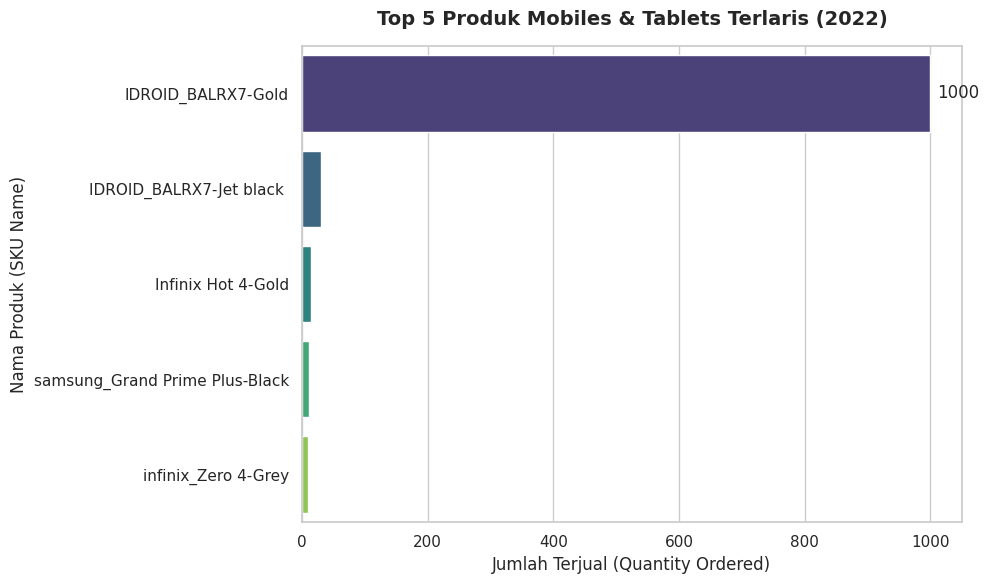

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mengatur tema visualisasi dan ukuran grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 2. Membuat bar chart (diagram batang) horizontal
# Menggunakan 'qty_ordered' untuk sumbu X dan 'sku_name' untuk sumbu Y
ax = sns.barplot(
    x="qty_ordered",
    y="sku_name",
    data=top_5_mobiles,
    palette="viridis"  # Memberikan gradasi warna yang estetis
)

# 3. Menambahkan label angka/jumlah di setiap batang grafik
ax.bar_label(ax.containers[0], padding=5)

# 4. Memberikan judul dan label pada sumbu grafik
plt.title("Top 5 Produk Mobiles & Tablets Terlaris (2022)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Jumlah Terjual (Quantity Ordered)", fontsize=12)
plt.ylabel("Nama Produk (SKU Name)", fontsize=12)

# 5. Mengatur agar tata letak tidak terpotong dan menampilkan grafik
plt.tight_layout()
plt.show()

## `No 2`
**Dear Data Analyst**,
<br></br>
Menindaklanjuti meeting gabungan Tim Werehouse dan Tim Marketing, kami menemukan bahwa ketersediaan stock produk dengan Kategori Others pada akhir 2022 kemarin masih banyak.
1. Kami mohon bantuan untuk melakukan pengecekan data penjualan kategori tersebut dengan tahun 2021 secara kuantitas penjualan. Dugaan sementara kami, telah terjadi penurunan kuantitas penjualan pada 2022 dibandingkan 2021. (Mohon juga menampilkan data ke-15 kategori)
<br></br>

2. Apabila memang terjadi penurunan kuantitas penjualan pada kategori Others, kami mohon bantuan untuk menyediakan data TOP 20 nama produk yang mengalami penurunan paling tinggi pada 2022 jika dibanding dengan 2021. Hal ini kami gunakan sebagai bahan diskusi pada meeting selanjutnya.  

Mohon bantuan untuk mengirimkan data tersebut paling lambat 4 hari dari hari ini. Atas bantuan yang diberikan, kami mengucapkan terima kasih.
<br></br>
Regards

**Tim Werehouse**

<details><summary>Klik di sini untuk tips</summary>


```python
1. Memfilter data dengan valid = 1
2. Memfilter data pada transaksi selama 2021
3. Memfilter data pada transaksi selama 2022
4. Gunakan groupby berdasarkan sku_name masing-masing tahun
5. Menggabungkan kedua data dengan merge
6. Lakukan pengurangan kolom qty 2022 dengan qty 2021


```



</details>

## `Jawaban No 2.1`

In [16]:
#Memfilter transaksi valid
df_valid = df[df['is_valid']==1].copy()
df_valid['year'] = df_valid['order_date'].dt.year
# ANALISIS TREN PENJUALAN PER KATEGORI TAHUN 2021-2022

# Menghitung Total Quantity Order Per Kategori
category_sales = df_valid.pivot_table (
index = 'category',
columns = 'year',
values = 'qty_ordered',
aggfunc = 'sum',
fill_value = 0
).reset_index()
category_sales.columns.name = None
category_sales.rename (columns = {2021:'qty_2021', 2022:'qty_2022'}, inplace = True)

category_sales['qty_growth'] = category_sales['qty_2022'] - category_sales['qty_2021']
category_sales['growth_pct'] = (category_sales['qty_growth'] / category_sales['qty_2021'] * 100)

# Mengurutkan Kategori Produk Berdasarkan Tren Penurunan Penjualan Terbesar
category_sales = category_sales.sort_values(by = 'qty_growth', ascending=True)

display(category_sales)

,category,qty_2021,qty_2022,qty_growth,growth_pct
10,Others,426,263,-163,-38.262911
12,Soghaat,759,612,-147,-19.367589
8,Men Fashion,237,175,-62,-26.160338
1,Beauty & Grooming,168,153,-15,-8.928571
2,Books,171,195,24,14.035088
0,Appliances,124,148,24,19.354839
5,Health & Sports,173,200,27,15.606936
3,Computing,109,153,44,40.366972
11,School & Education,184,237,53,28.804348
6,Home & Living,193,250,57,29.533679


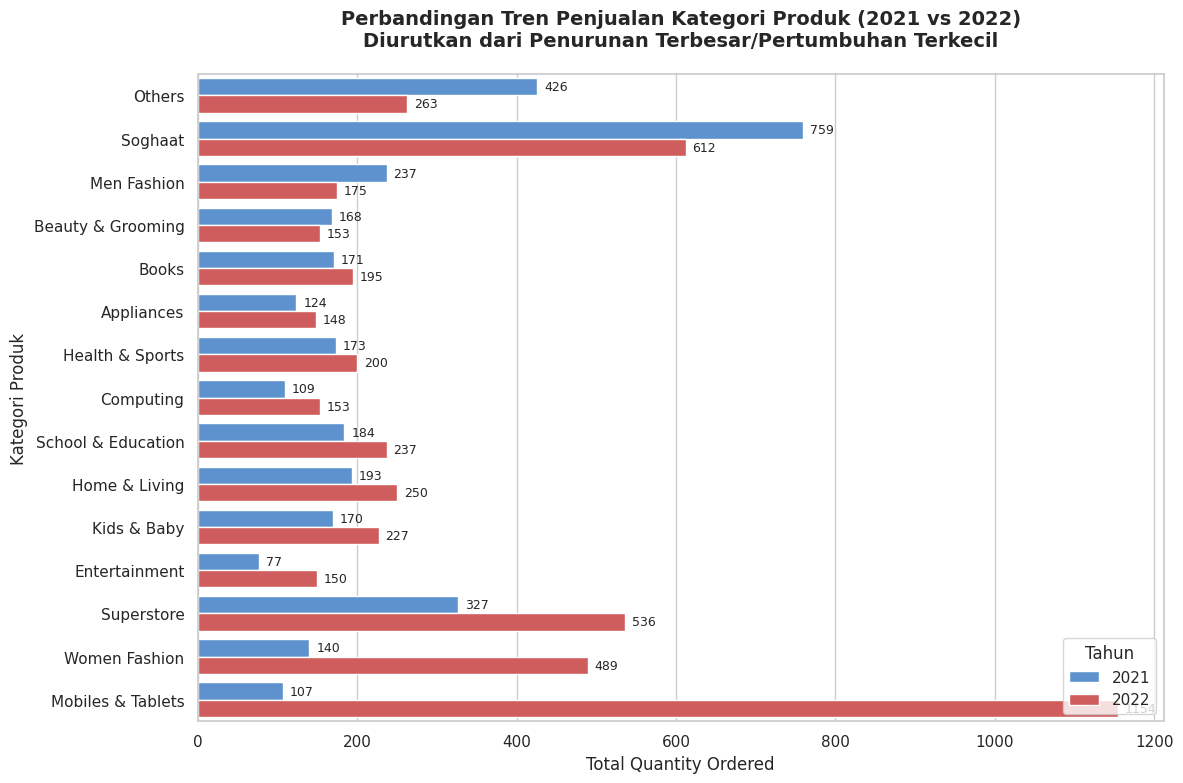

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Mengubah struktur data dari format lebar (wide) ke format panjang (long) agar cocok dengan Seaborn
category_sales_melted = pd.melt(
    category_sales,
    id_vars=['category'],
    value_vars=['qty_2021', 'qty_2022'],
    var_name='Tahun',
    value_name='Quantity'
)

# Mengubah label tahun agar lebih rapi saat dibaca di grafik
category_sales_melted['Tahun'] = category_sales_melted['Tahun'].map({'qty_2021': '2021', 'qty_2022': '2022'})

# 2. Mengatur tema dan ukuran grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 8))

# 3. Membuat Grouped Bar Chart secara horizontal
ax = sns.barplot(
    x="Quantity",
    y="category",
    hue="Tahun",
    data=category_sales_melted,
    palette=["#4a90e2", "#e24a4a"]  # Biru untuk 2021, Merah untuk 2022
)

# 4. Menambahkan label angka di setiap ujung batang grafik
for container in ax.containers:
    ax.bar_label(container, padding=5, fmt='%d', fontsize=9)

# 5. Memberikan judul dan label sumbu
plt.title("Perbandingan Tren Penjualan Kategori Produk (2021 vs 2022)\nDiurutkan dari Penurunan Terbesar/Pertumbuhan Terkecil", fontsize=14, fontweight="bold", pad=20)
plt.xlabel("Total Quantity Ordered", fontsize=12)
plt.ylabel("Kategori Produk", fontsize=12)
plt.legend(title="Tahun", loc="lower right")

# 6. Menyesuaikan tata letak agar tidak terpotong
plt.tight_layout()
plt.show()

## `Jawaban No 2.2`

In [17]:
# Filter data Others, valid = 1, tahun 2021 & 2022
df_others = df_valid[
    (df_valid['is_valid'] == 1) &
    (df_valid['category'] == 'Others') &
    (df_valid['order_date'].dt.year.isin([2021, 2022]))
]

# Grouping qty per SKU & tahun
grouped = (
    df_others
    .groupby(['sku_name', df_others['order_date'].dt.year])['qty_ordered']
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)

# Rename kolum
grouped.columns = ['sku_name', 'qty_ordered_21', 'qty_ordered_22']

# Hitung selisih
grouped['selisih_qty_others'] = grouped['qty_ordered_22'] - grouped['qty_ordered_21']

# Sort & ambil top 20 penurunan
compare_produk_others = grouped.sort_values(by='selisih_qty_others', ascending=True)

compare_produk_others.head(20)

,sku_name,qty_ordered_21,qty_ordered_22,selisih_qty_others
69,RB_Dettol Germ Busting Kit-bf,200,45,-155
18,Dawlance_MD 10 + DWB 600,23,0,-23
84,Telemall_MM-DR-HB-L,23,2,-21
137,iu_Tickets General Enclosure-Islamabad,20,0,-20
70,RS_Rehmat-e-Shereen Mix Mithai,13,0,-13
141,kansai_NeverWet,10,1,-9
154,sindbad_Sindbad Gift Card-3,7,0,-7
133,emart_00-1,7,1,-6
93,Vouch 365 2016,5,0,-5
4,Am-PTV_ATS-004-M,5,0,-5


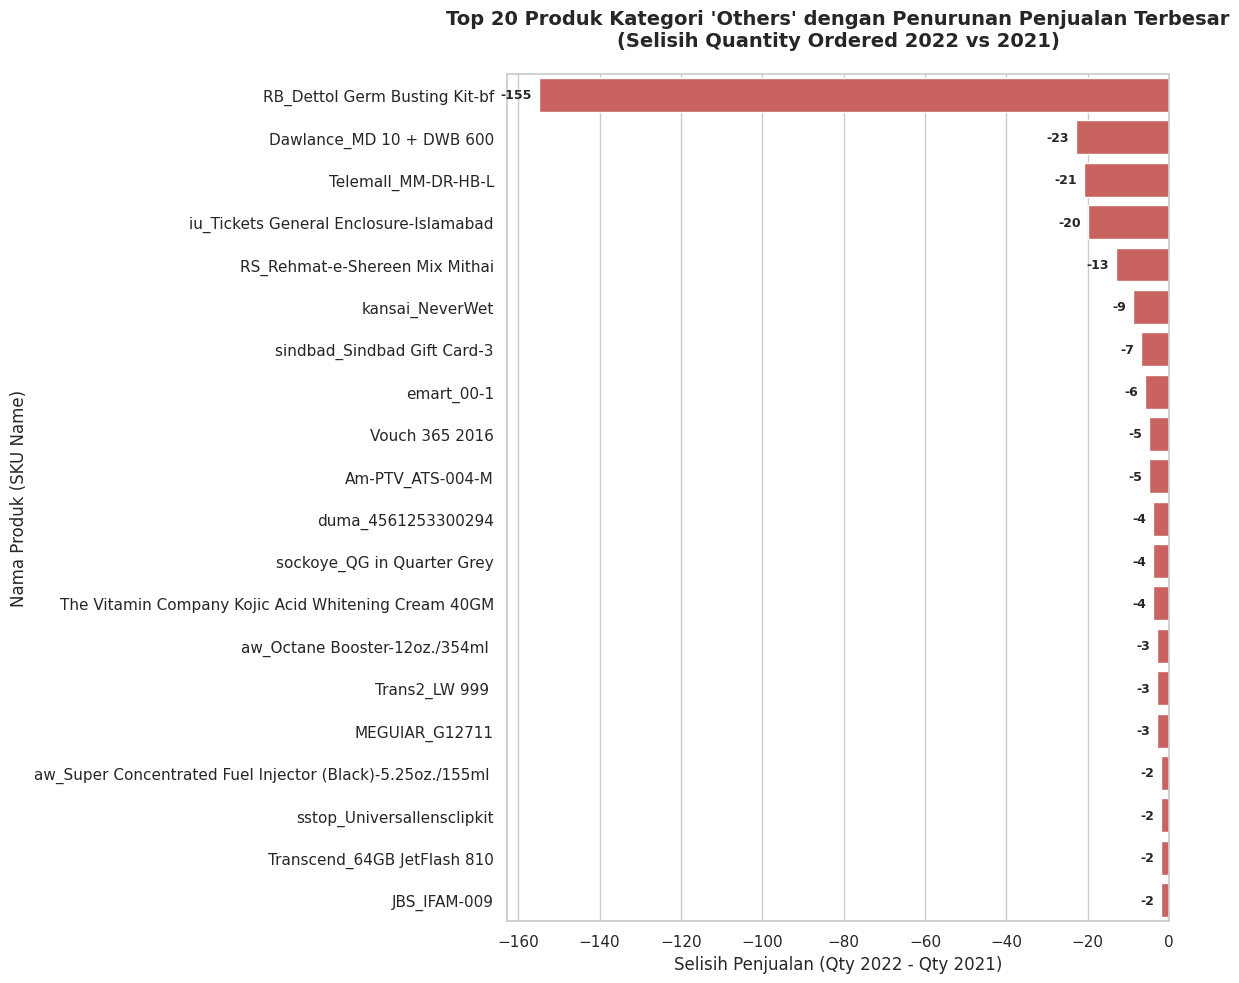

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mengambil top 20 produk dengan penurunan terbesar (nilai selisih paling negatif)
top_20_drop = compare_produk_others.head(20).copy()

# 2. Mengatur tema dan ukuran grafik yang lebih tinggi agar muat 20 produk
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 10))

# 3. Membuat grafik batang horizontal untuk nilai selisihnya
ax = sns.barplot(
    x="selisih_qty_others",
    y="sku_name",
    data=top_20_drop,
    color="#d9534f"  # Warna merah untuk melambangkan penurunan/negatif
)

# 4. Menambahkan label angka penurunan di setiap ujung batang grafik
ax.bar_label(ax.containers[0], padding=5, fmt='%d', fontsize=9, fontweight='bold')

# 5. Memberikan judul dan label sumbu
plt.title("Top 20 Produk Kategori 'Others' dengan Penurunan Penjualan Terbesar\n(Selisih Quantity Ordered 2022 vs 2021)",
          fontsize=14, fontweight="bold", pad=20)
plt.xlabel("Selisih Penjualan (Qty 2022 - Qty 2021)", fontsize=12)
plt.ylabel("Nama Produk (SKU Name)", fontsize=12)

# 6. Menyesuaikan tata letak agar teks nama produk tidak terpotong
plt.tight_layout()
plt.show()

## `No 3`
**Dear Data Analyst**,
<br></br>
Terkait ulang tahun perusahaan pada 2 bulan mendatang, Tim Digital Marketing akan memberikan informasi promo bagi pelanggan pada akhir bulan ini. Kriteria pelanggan yang akan kami butuhkan adalah mereka yang sudah melakukan check-out namun belum melakukan pembayaran (is_gross = 1) selama tahun 2022. Data yang kami butuhkan adalah ID Customer dan Registered Date.

Mohon bantuan, untuk mengirimkan data tersebut sebelum akhir bulan ini ke Tim Digital Marketing. Atas bantuan yang diberikan, kami mengucapkan terima kasih.
<br></br>
Regards

**Tim Digital Marketing**

<details><summary>Klik di sini untuk tips</summary>


```python
1. Memfilter data dengan gross = 1
2. Memfilter data dengan valid = 0
3. Memfilter data dengan net = 0
4. Memfilter data pada transaksi selama 2022


```



</details>

## `Jawaban No 3`

In [26]:
#Filter data sesuai kriteria
df_tokopaedi = (
    df[
        (df['is_gross'] == 1) &
        (df['is_valid'] == 0) &
        (df['is_net'] == 0) &
        (df['order_date'].dt.year == 2022)
    ]
)
#Ambil data customer_id dan registered_date
customer_checkout = (
    df_tokopaedi[['customer_id', 'registered_date']]
    .drop_duplicates()
    .sort_values(by='registered_date')
    .reset_index(drop=True)
)
#Menampilkan data
customer_checkout

,customer_id,registered_date
0,C849967L,2021-07-02
1,C349980L,2021-07-02
2,C831683L,2021-07-03
3,C893754L,2021-07-03
4,C378684L,2021-07-03
...,...,...
815,C877563L,2022-08-24
816,C741725L,2022-08-25
817,C788348L,2022-08-25
818,C466867L,2022-08-28


/tmp/ipykernel_3956/3371524657.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tokopaedi['Month_Num'] = df_tokopaedi['order_date'].dt.month
/tmp/ipykernel_3956/3371524657.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tokopaedi['Bulan'] = df_tokopaedi['order_date'].dt.strftime('%B')


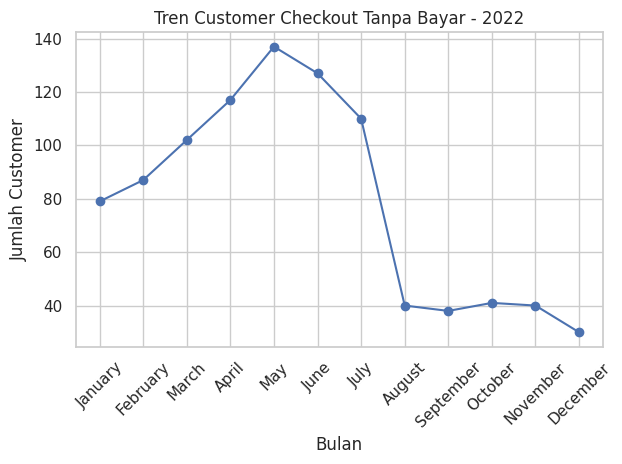

In [31]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Tambahkan kolom Bulan Angka (1-12) dan Nama Bulan dari df_tokopaedi
df_tokopaedi['Month_Num'] = df_tokopaedi['order_date'].dt.month
df_tokopaedi['Bulan'] = df_tokopaedi['order_date'].dt.strftime('%B')

# 2. Kelompokkan berdasarkan Bulan Angka & Nama Bulan untuk menghitung unik customer
monthly_trend = (
    df_tokopaedi.groupby(['Month_Num', 'Bulan'])['customer_id']
    .nunique()
    .reset_index(name='Total_cust')
)
# 3. Urutkan secara kronologis berdasarkan angka bulannya (1 sampai 12)
monthly_trend = monthly_trend.sort_values(by='Month_Num').reset_index(drop=True)

# 4. Jalankan grafik
plt.figure()
plt.plot(monthly_trend['Bulan'].astype(str),
         monthly_trend['Total_cust'],
         marker='o')
plt.xticks(rotation=45)
plt.title('Tren Customer Checkout Tanpa Bayar - 2022')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Customer')
plt.tight_layout()
plt.show()

## `No 4`
**Dear Data Analyst**,
<br></br>
Pada bulan October hingga Desember 2022, kami melakukan campaign setiap hari Sabtu dan Minggu. Kami hendak menilai, apakah campaign tersebut cukup berdampak pada kenaikan penjualan (before_discount). Mohon bantuan untuk menampilkan data:
1. Rata-rata harian penjualan weekends (Sabtu dan Minggu) vs rata-rata harian penjualan weekdays (Senin-Jumat) per bulan tersebut. Apakah ada peningkatan penjualan pada masing-masing bulan tersebut.
2. Rata-rata harian penjualan weekends (Sabtu dan Minggu) vs rata-rata harian penjualan weekdays (Senin-Jumat) keseluruhan 3 bulan tersebut.

Mohon bantuan untuk mengirimkan data tersebut paling lambat minggu depan. Atas bantuan yang diberikan, kami mengucapkan terima kasih.
<br></br>
Regards

**Tim Campaign**

<details><summary>Klik di sini untuk tips</summary>


```python
1. Buatlah kolom baru untuk day, month, dan month number
2. Memfilter data dengan valid = 1
3. Memfilter data dengan day termasuk 'Saturday', 'Sunday' dengan menggunakan fungsi isin dan simpan dalam variable 'weekends'
4. Memfilter data dengan day termasuk 'Monday','Tuesday','Wednesday','Thusday','Friday' dengan menggunakan fungsi isin dan simpan dengan variabel 'weekday'
5. Memfilter data pada transaksi selama 2022 bulan Oktober sampai dengan Desember
6. Gunakan groupby berdasarkan pada masing-masing variabel
7. Menggabungkan kedua data dengan merge
8. Tampilkan pada grafik batang untuk melihat perbedaananya


```



</details>

## `Jawaban No 4.1`

In [20]:
# kolom baru untuk day, month, dan month number
df['day'] = df['order_date'].dt.day_name()
df['month'] = df['order_date'].dt.month_name()
df['month_num'] = df['order_date'].dt.month

# Filter valid = 1 & rentang Okt - Des 2022
df_filtered = df[
    (df['is_valid'] == 1) &
    (df['order_date'].dt.year == 2022) &
    (df['month_num'].isin([10, 11, 12]))
]
# Filter day 'Saturday', 'Sunday' pakai isin -> 'weekends'
weekends = df_filtered[df_filtered['day'].isin(['Saturday', 'Sunday'])]
# Filter day Senin-Jumat pakai isin -> 'weekdays'
weekdays = df_filtered[df_filtered['day'].isin(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'])]
# Hitung total harian untuk weekends
weekends_daily = weekends.groupby(['month_num', 'month', weekends['order_date'].dt.date])['before_discount'].sum().reset_index()
avg_weekends = weekends_daily.groupby(['month_num', 'month'], as_index=False)['before_discount'].mean()
# Hitung total harian untuk weekdays
weekdays_daily = weekdays.groupby(['month_num', 'month', weekdays['order_date'].dt.date])['before_discount'].sum().reset_index()
avg_weekdays = weekdays_daily.groupby(['month_num', 'month'], as_index=False)['before_discount'].mean()
# Menggabungkan kedua data dengan merge
merged_data = round(pd.merge(avg_weekdays, avg_weekends, on=['month_num', 'month'], suffixes=('_weekday', '_weekend')),1)
# Urutkan bulan dari Okt ke Des (berdasarkan month_num)
merged_data = merged_data.sort_values('month_num')
# Ganti nama kolom biar legend grafiknya bagus
merged_data = merged_data.rename(columns={
    'before_discount_weekday': 'Rata-Rata Weekday',
    'before_discount_weekend': 'Rata-Rata Weekend'
})
display(merged_data)

,month_num,month,Rata-Rata Weekday,Rata-Rata Weekend
0,10,October,7872212.4,5708340.7
1,11,November,6204666.0,5774045.0
2,12,December,8542530.0,4105994.0


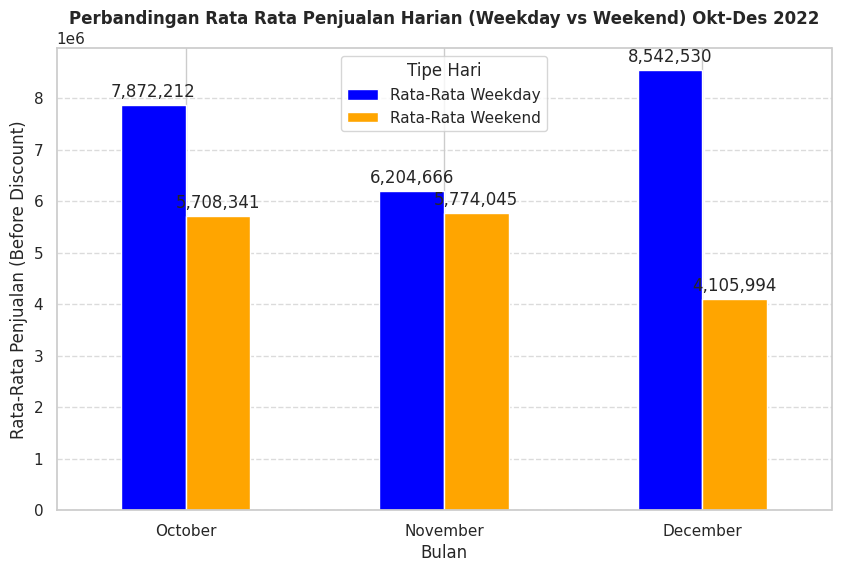

In [21]:
# Bikin plot bar
ax = merged_data.plot(
    x='month',
    y=['Rata-Rata Weekday', 'Rata-Rata Weekend'],
    kind='bar',
    figsize=(10, 6),
    color=['blue', 'orange'] # Warna biru dan oranye
)
# Tambahkan angka di atas setiap batang
for container in ax.containers:
    labels = [f"{value:,.0f}" for value in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3)
# Menambahkan judul dan label agar informatif
plt.title('Perbandingan Rata Rata Penjualan Harian (Weekday vs Weekend) Okt-Des 2022', fontweight='bold')
plt.xlabel('Bulan')
plt.ylabel('Rata-Rata Penjualan (Before Discount)')
plt.xticks(rotation=0) # Biar nama bulannya mendatar (nggak miring)
plt.legend(title='Tipe Hari')
plt.grid(axis='y', linestyle='--', alpha=0.7) # Kasih garis bantu tipis

# Tampilkan grafik
plt.show()

## `Jawaban No 4.2`

In [37]:
#Jawaban nomor 4.2
data_42 = df[
    (df['order_date'].dt.year == 2022) &
    (df['order_date'].dt.month.isin([10, 11, 12])) &
    (df['is_valid'] == 1)
].copy()

# Tentukan weekend dan weekday
data_42['day_type'] = data_42['order_date'].dt.day_name().apply(
    lambda x: 'Weekend' if x in ['Saturday', 'Sunday'] else 'Weekday'
)
# Hitung total penjualan setiap tanggal
daily_sales = (
    data_42.groupby(['order_date', 'day_type'])['before_discount']
    .sum()
    .reset_index()
)
# Hitung rata-rata harian weekend vs weekday selama 3 bulan
result_42 = (
    daily_sales.groupby('day_type')['before_discount']
    .mean()
    .reset_index()
)
# Hitung persentase perbedaan
weekend = result_42.loc[
    result_42['day_type'] == 'Weekend', 'before_discount'
].iloc[0]

weekday = result_42.loc[
    result_42['day_type'] == 'Weekday', 'before_discount'
].iloc[0]

difference = ((weekend - weekday) / weekday) * 100

print(f"\nRata-rata Weekend : Rp{weekend:,.0f}")
print(f"Rata-rata Weekday : Rp{weekday:,.0f}")
print(f"Perbedaan         : {difference:.2f}%")



Rata-rata Weekend : Rp5,269,300
Rata-rata Weekday : Rp7,520,249
Perbedaan         : -29.93%


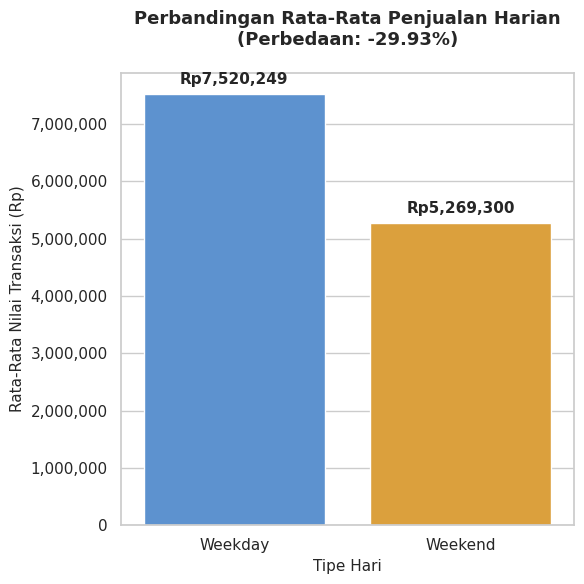

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mengatur tema dan ukuran grafik
sns.set_theme(style="whitegrid")
plt.figure(figsize=(6, 6))

# 2. Membuat diagram batang vertikal
# Menggunakan 'day_type' untuk sumbu X dan 'before_discount' untuk sumbu Y
ax = sns.barplot(
    x="day_type",
    y="before_discount",
    data=result_42,
    palette=["#4a90e2", "#f5a623"],  # Warna biru untuk Weekday, Oranye untuk Weekend
    hue="day_type",                  # Menghindari warning pada Seaborn versi terbaru
    legend=False
)
# 3. Menambahkan label nilai mata uang di atas masing-masing batang
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f'Rp{height:,.0f}',
        (p.get_x() + p.get_width() / 2., height),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        xytext=(0, 5),
        textcoords='offset points'
    )
# 4. Memberikan judul dan label sumbu
plt.title(f"Perbandingan Rata-Rata Penjualan Harian\n(Perbedaan: {difference:.2f}%)",
          fontsize=13, fontweight="bold", pad=20)
plt.xlabel("Tipe Hari", fontsize=11)
plt.ylabel("Rata-Rata Nilai Transaksi (Rp)", fontsize=11)

# 5. Mengatur format angka pada sumbu Y agar menggunakan ribuan (,0f)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, loc: f"{x:,.0f}"))

# 6. Menyesuaikan tata letak agar tidak terpotong
plt.tight_layout()
plt.show()